# Qiskit toolkit for the Geometry-Aware Quantum Cloud Challenge

This notebook teaches the tools you need for Levels 1–3 using small **practice examples**: a 6-qubit ring instead of the challenge graphs, and the Bell state $|\Psi^+\rangle$ instead of the challenge's $|\Phi^+\rangle$. **It does not solve the challenge.** Each section ends with a **→ In the challenge** note that says where the idea applies. Do the real work in the challenge submission notebook, using the official graphs, ports and noise models from the starter kit.

| Section | Tool | You'll need it for |
|---|---|---|
| 1 | Coupling graphs, SWAP cost, circuit metrics | Level 1 |
| 2 | Checking where routing left your qubits | Level 1 |
| 3 | Measuring in X/Y/Z and scoring correlators | Level 1 |
| 4 | Noise models and fake backends | Level 2 |
| 5 | Bootstrap error bars | Level 2 |
| 6 | Ancilla parity checks and postselection | Level 3 |

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import qiskit
import qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler import CouplingMap
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError, depolarizing_error

SEED, SHOTS = 7, 4_000
print(f"Qiskit {qiskit.__version__} | Aer {qiskit_aer.__version__}")

Qiskit 2.4.1 | Aer 0.17.2


## 1. Coupling graphs and SWAP cost

A `CouplingMap` lists the qubit pairs that can run a two-qubit gate. If two qubits aren't neighbours, the transpiler inserts SWAPs, and **each SWAP costs 3 CNOTs**. `transpile` compiles a circuit for a chip: it places your circuit's (virtual) qubits on the chip's physical qubits (*layout*), inserts SWAPs (*routing*), and rewrites gates into the chip's native set. Our practice graph is a 6-qubit ring.

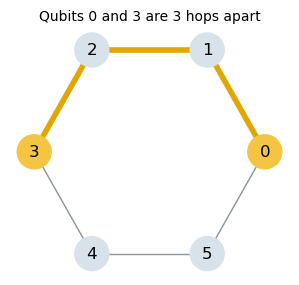

In [2]:
ring = CouplingMap.from_ring(6)                       # practice graph: 0-1-2-3-4-5-0
graph = nx.Graph(list(ring.get_edges()))
path = nx.shortest_path(graph, 0, 3)

fig, ax = plt.subplots(figsize=(3.6, 3.2))
pos = nx.circular_layout(sorted(graph))
nx.draw_networkx(graph, pos, ax=ax, node_size=600, edge_color="#8a949c",
                 node_color=["#f4c542" if n in (0, 3) else "#d8e2ea" for n in graph])
nx.draw_networkx_edges(graph, pos, edgelist=list(zip(path, path[1:])), ax=ax, width=4, edge_color="#e1a600")
ax.set_title(f"Qubits 0 and 3 are {ring.distance(0, 3)} hops apart", fontsize=10)
ax.axis("off")
plt.show()

Now ask for a CNOT between qubits 0 and 3, then count what it costs. `two_qubit_gates` works for any gate set (`cx`, `cz`, `ecr`, ...).

In [3]:
def two_qubit_gates(qc):
    return sum(len(i.qubits) == 2 and i.operation.name != "barrier" for i in qc.data)

qc = QuantumCircuit(6)
qc.cx(0, 3)
layout = list(range(6))                               # pin virtual qubit i to physical qubit i
routed = transpile(qc, coupling_map=ring, initial_layout=layout, seed_transpiler=SEED, optimization_level=0)
compiled = transpile(qc, coupling_map=ring, basis_gates=["u", "cx"], initial_layout=layout,
                     seed_transpiler=SEED, optimization_level=0)
print("routed:  ", dict(routed.count_ops()))
print("compiled:", dict(compiled.count_ops()), "| depth", compiled.depth(), "| 2q gates", two_qubit_gates(compiled))

routed:   {'swap': 2, 'cx': 1}
compiled: {'cx': 7} | depth 4 | 2q gates 7


**→ In the challenge:** load each official graph into a `CouplingMap`. The distance between the two ports sets the minimum routing cost. For official submissions, follow the README common reporting conventions: report ZZ circuit depth including measurements (excluding barriers), native two-qubit gates after decomposition, and SWAPs before decomposition; supply XX and YY costs separately. Count SWAPs *before* they are expanded into CNOTs (as in `routed`, or the `qc.swap` calls you wrote by hand).

## 2. Routing moves your qubits

The router is free to leave a qubit somewhere other than where it started. `initial_layout` only fixes the **start**. Always check where your qubits **end**.

In [4]:
def measured_qubits(tqc):
    # {classical bit: physical qubit it measured} for a transpiled circuit.
    return {tqc.find_bit(i.clbits[0]).index: tqc.find_bit(i.qubits[0]).index
            for i in tqc.data if i.operation.name == "measure"}

qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
routed_bell = transpile(qc, coupling_map=ring, initial_layout=[0, 3], seed_transpiler=SEED, optimization_level=1)
print("started on [0, 3]; clbits now read physical qubits", measured_qubits(routed_bell))

try:                                                  # "none" forbids the router from adding SWAPs
    transpile(qc, coupling_map=ring, initial_layout=[0, 3], routing_method="none", optimization_level=1)
except Exception as err:
    print("routing_method='none':", str(err).split(" CheckMap")[0].strip("'."))

started on [0, 3]; clbits now read physical qubits {0: 1, 1: 2}
routing_method='none': No routing method selected, but circuit is not routed to device


**→ In the challenge:** the pair must *finish* on the two ports, and as shown above, `initial_layout` alone doesn't guarantee that. Making it land there is part of Level 1. Useful facts and tools:
- `qc.swap(a, b)` lets you write SWAPs yourself.
- `routing_method="none"` stops the transpiler adding SWAPs. Without it, `optimization_level` ≥ 2 may also delete SWAPs you wrote and relabel the qubits.
- Give `initial_layout` a position for **every** circuit qubit. Otherwise the layout pass may move your whole circuit.
- `tqc.layout.final_index_layout()` shows where each virtual qubit ended up.

Whatever you choose, **assert** the result with `measured_qubits` on every circuit you run.

## 3. Measuring in X, Y and Z

Hardware measures only Z. To read X, apply `H` first. To read Y, apply `S†` then `H`. Watch the **bit order**: in a Qiskit counts key, the *rightmost* character is classical bit 0. With several classical registers, the key also contains spaces (`'1 01'`), so `bits` below strips them.

In [5]:
qc = QuantumCircuit(2, 2)
qc.x(0)                                               # flip qubit 0 only
qc.measure([0, 1], [0, 1])
print("X on qubit 0 gives key", AerSimulator(seed_simulator=SEED).run(qc, shots=1).result().get_counts())

def bits(key):
    # Counts key -> string where bits(key)[i] is classical bit i.
    return key.replace(" ", "")[::-1]

def rotate(qc, qubits, basis):
    # Append gates so a Z measurement of `qubits` reads `basis` ("X", "Y" or "Z").
    for q in qubits:
        if basis == "Y":
            qc.sdg(q)
        if basis in ("X", "Y"):
            qc.h(q)

def correlator(counts, i=0, j=1):
    # Mean of (+1 if clbits i and j agree, else -1) over all shots.
    agree = sum(n for key, n in counts.items() if bits(key)[i] == bits(key)[j])
    return (2 * agree - sum(counts.values())) / sum(counts.values())

def psi_plus(qc, a=0, b=1):
    # Practice state (|01> + |10>)/sqrt(2). The challenge uses |Phi+> instead.
    qc.h(a)
    qc.cx(a, b)
    qc.x(b)

for basis in "ZXY":
    qc = QuantumCircuit(2, 2)
    psi_plus(qc)
    rotate(qc, [0, 1], basis)
    qc.measure([0, 1], [0, 1])
    counts = AerSimulator(seed_simulator=SEED).run(qc, shots=SHOTS).result().get_counts()
    print(f"<{basis}{basis}> = {correlator(counts):+.3f}")

X on qubit 0 gives key {'01': 1}
<ZZ> = -1.000
<XX> = +1.000
<YY> = +1.000


$|\Psi^+\rangle$ gives $\langle ZZ\rangle=-1$, $\langle XX\rangle=+1$, $\langle YY\rangle=+1$. The challenge's $|\Phi^+\rangle$ has a different sign pattern. That pattern is why the brief's $F = (1 + \langle XX\rangle - \langle YY\rangle + \langle ZZ\rangle)/4$ has the signs it does.

**→ In the challenge:** for each graph, build $|\Phi^+\rangle$ on the ports, run it once per basis, and combine the three correlators into $F$ (Level 1 is noiseless, so expect $F \approx 1$).

## 4. Adding noise

Aer noise attaches to **gate names**, so your circuit has to be compiled to the gates the noise model knows. You have two options:

**Option A: build your own** `NoiseModel`, for synthetic and circuit-level models (an error after every gate and on every readout, like `toy_noise` below). Compile with `basis_gates=["u", "cx"]`, the gate names it lists, so every gate picks up noise:

In [6]:
def toy_noise(p1=0.002, p2=0.02, p_meas=0.015):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p1, 1), ["u"])      # every 1q gate
    nm.add_all_qubit_quantum_error(depolarizing_error(p2, 2), ["cx"])     # every CNOT
    nm.add_all_qubit_readout_error(ReadoutError([[1 - p_meas, p_meas], [p_meas, 1 - p_meas]]))
    return nm

noisy = AerSimulator(noise_model=toy_noise(), seed_simulator=SEED)

**Option B: use a fake backend**, which brings its own coupling map, native gates and calibrated noise. `GenericBackendV2` is a stand-in here; the starter kit names the real one. Real snapshots load like `from qiskit_ibm_runtime.fake_provider import FakeBrisbane` (this needs `qiskit-ibm-runtime`). Transpile **against the simulator** so the circuit uses the backend's gates.

In [7]:
backend = GenericBackendV2(num_qubits=5, coupling_map=CouplingMap.from_line(5), seed=SEED)   # sparse, like real chips
backend_sim = AerSimulator.from_backend(backend)
a, b = backend.coupling_map.get_edges()[0]           # any connected pair, for practice

qc = QuantumCircuit(2, 2)
psi_plus(qc)
qc.measure([0, 1], [0, 1])
tqc = transpile(qc, backend_sim, initial_layout=[a, b], seed_transpiler=SEED)
counts = backend_sim.run(tqc, shots=SHOTS, seed_simulator=SEED).result().get_counts()
print("native gates:", sorted(backend.operation_names))
print("compiled:", dict(tqc.count_ops()), f"| <ZZ> = {correlator(counts):+.3f}")

native gates: ['cx', 'delay', 'id', 'measure', 'reset', 'rz', 'sx', 'x']
compiled: {'rz': 2, 'measure': 2, 'sx': 1, 'cx': 1, 'x': 1} | <ZZ> = -0.981


**Common mistakes:**
- Compiling to `["u", "cx"]` and then running on `AerSimulator.from_backend` fails with `unknown instruction`. For a fake backend, re-transpile your circuit against it (same layout and seed) rather than reusing a `u`/`cx` version.
- Any gate whose name the noise model doesn't list runs **noiselessly**, with no warning. If you forget `basis_gates=["u", "cx"]` with `toy_noise()`, your `swap` and `h` gates are perfect and F comes out too high. The same thing happens with `NoiseModel.from_backend`.
- `optimization_level` ≥ 1 may delete gates that cancel out. Set it explicitly and report it.

## 5. Error bars with the bootstrap

Shot noise means one number on its own can't be compared with another. The **bootstrap** fixes that: resample the shots with replacement many times, recompute your statistic each time, and take the 2.5th and 97.5th percentiles as a 95% interval.

The experiment below appends useless `CX·CX` pairs, which cancel to the identity, so the state is unchanged but noise builds up. What happens to the signal as gates are added?

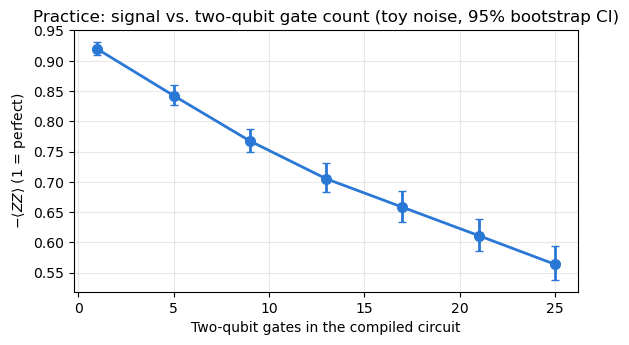

In [8]:
def shot_values(counts, i=0, j=1):
    # One +1/-1 entry per shot (+1 if clbits i and j agree).
    return np.concatenate([np.full(n, 1 if bits(k)[i] == bits(k)[j] else -1) for k, n in counts.items()])

def bootstrap_ci(values, stat=np.mean, n=500, seed=SEED):
    rng = np.random.default_rng(seed)
    return np.percentile([stat(rng.choice(values, size=len(values))) for _ in range(n)], [2.5, 97.5])

points = []
for extra_pairs in range(0, 13, 2):
    qc = QuantumCircuit(2, 2)
    psi_plus(qc)
    for _ in range(extra_pairs):
        qc.cx(0, 1)
        qc.cx(0, 1)
    qc.measure([0, 1], [0, 1])
    tqc = transpile(qc, basis_gates=["u", "cx"], optimization_level=0)   # level 0 keeps the pairs
    values = -shot_values(noisy.run(tqc, shots=SHOTS).result().get_counts())  # -<ZZ>: 1 is perfect
    lo, hi = bootstrap_ci(values)
    points.append((two_qubit_gates(tqc), values.mean(), lo, hi))

x, y, lo, hi = np.array(points).T
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.errorbar(x, y, yerr=[y - lo, hi - y], fmt="o-", ms=7, lw=2, capsize=3, color="#2a78d6")
ax.set(xlabel="Two-qubit gates in the compiled circuit", ylabel=r"$-\langle ZZ\rangle$ (1 = perfect)",
       title="Practice: signal vs. two-qubit gate count (toy noise, 95% bootstrap CI)")
ax.grid(alpha=0.3)
plt.show()

**→ In the challenge:** $F$ combines three bases. Run each basis with its own seed (e.g. `seed_simulator=SEED + k`); with one shared seed, all three runs get identical noise draws. In each bootstrap round, resample **each basis's shots separately**, compute $F$ from the three resampled means, and take percentiles of those $F$ values. Don't combine three separate intervals. `bootstrap_ci` handles one array, so you write that loop yourself. Your Level 2 plot shows fidelity against two-qubit gates and SWAPs.

## 6. Parity checks and postselection

A parity check copies a property of the data qubits onto an **ancilla** without measuring the data. Applying a CNOT from each data qubit into the ancilla leaves it holding $q_0 \oplus q_1$ (the $ZZ$ parity). If the ancilla shows the wrong parity, you **discard** the shot, and the fraction you keep is the **yield**.

$|\Psi^+\rangle$ has *odd* parity, so a healthy shot reads ancilla `= 1`. Here we compile without a coupling map (all-to-all), so the ancilla needs no routing. On the challenge graphs it will.

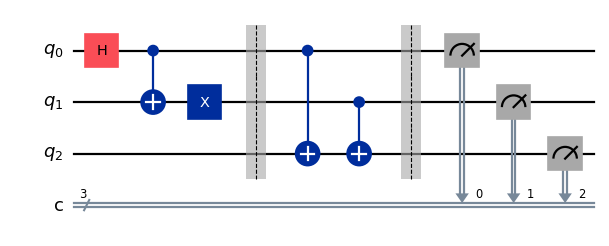

In [9]:
def psi_plus_checked(fault=None):
    qc = QuantumCircuit(3, 3)                        # qubits 0, 1 = data; qubit 2 = ancilla
    psi_plus(qc)
    if fault:
        getattr(qc, fault)(0)                         # inject an error on purpose, e.g. "x"
    qc.barrier()
    qc.cx(0, 2)
    qc.cx(1, 2)
    qc.barrier()
    qc.measure([0, 1, 2], [0, 1, 2])
    return qc

def postselect(counts, clbit, keep):
    kept = {k: n for k, n in counts.items() if bits(k)[clbit] == keep}
    return kept, sum(kept.values()) / sum(counts.values())

psi_plus_checked().draw("mpl", scale=0.8)

In [10]:
runs = {"noiseless, X fault on qubit 0": (AerSimulator(seed_simulator=SEED), "x"),
        "toy noise, no fault": (noisy, None)}
for label, (sim, fault) in runs.items():
    tqc = transpile(psi_plus_checked(fault), basis_gates=["u", "cx"], optimization_level=0)
    counts = sim.run(tqc, shots=SHOTS).result().get_counts()
    kept, yield_ = postselect(counts, clbit=2, keep="1")
    after = f"{correlator(kept):+.3f}" if kept else "n/a (nothing kept)"
    print(f"{label:30s} <ZZ> all shots {correlator(counts):+.3f} | kept shots {after} | yield {yield_:.3f}")

noiseless, X fault on qubit 0  <ZZ> all shots +1.000 | kept shots n/a (nothing kept) | yield 0.000
toy noise, no fault            <ZZ> all shots -0.886 | kept shots -0.927 | yield 0.951


**Try it:** change the fault to `"z"`. What does this check miss?

**→ In the challenge (Level 3), questions to answer:**
- What parity should a healthy $|\Phi^+\rangle$ shot show?
- Where can the ancilla sit on each graph, and what does it cost to route it to the ports and back?
- The official rule applies the check *before* the basis rotations, in all three bases. Why does that order matter? On the practice state, try placing it *after* the `XX` rotation instead and compare what the ancilla reports.
- Does the conditional fidelity gain make up for the extra gates and the discarded shots? Report yield and discarded shots either way.

## What to report for every case

For each case, report **F with its 95% CI**, depth, two-qubit gates, SWAPs, physical qubits including ancillas (the qubits your compiled circuit actually touches; after compiling to a backend, `tqc.num_qubits` is the whole device), and yield with the number of discarded shots. Also give the seed, shot count and transpiler settings so anyone can reproduce your numbers. When you compare architectures, separate connectivity effects (SWAPs) from differences in gate error. One finite model never proves that one geometry is better.

*References:* [Qiskit transpiler](https://quantum.cloud.ibm.com/docs/en/guides/transpile) · [Aer noise models](https://qiskit.github.io/qiskit-aer/tutorials/3_building_noise_models.html) · [IBM long-range entanglement tutorial](https://quantum.cloud.ibm.com/docs/en/tutorials/long-range-entanglement)